# nanojaxterity: from a robot *description* to a learned balancing controller

**Abstract.** We take a cartpole defined by a URDF, calibrate its simulation
parameters, build a fast differentiable simulator from it, and train a small
reinforcement-learning policy that balances the pole — the whole journey in one
JAX-native stack. The point is not the controller (balancing a cartpole is a
solved, easy problem) but the *lane*: one connected toolchain from a robot
description to a learned controller that is destined for verified embedded
deployment. By the end you will be able to load a calibrated robot, turn it into
a `jit`/`vmap`-able environment, evaluate a trained policy, and read off where
this approach helps and where it doesn't.

*Estimated reading time: ~15 min. Runtime: <1 min on CPU — the notebook loads a
committed pretrained policy rather than retraining (training is ~6 min and lives
in `examples/nanojaxterity.py`).*

## Prerequisites

- Comfort with **JAX** (`jit`, `vmap`, `grad`) and array programming.
- A passing familiarity with **policy-gradient RL** (PPO) — we explain the
  shape but not the derivation; see Schulman et al. (2017) in the references.
- Knowing what an **inverted pendulum** is. That's it.

This tutorial uses the `jaxterity` robotics layer (built on
[`jaxonomy`](https://github.com/) + MuJoCo's MJX). Two pieces do the heavy
lifting and are worth knowing by name: `jaxterity.zoo` (the robot zoo) and
`Robot.functional_dynamics()` (the fast simulator primitive we introduce below).

## The problem: the gap between a model and a controller

Suppose you have a robot. You probably have a **description** of it — a URDF or
MJCF file with links, joints, masses. What you *want* is a **controller**: code
that reads the robot's state and commands its actuators to do something useful,
and that eventually runs on the real hardware.

Between those two is a surprising amount of plumbing: turn the description into a
simulation, *calibrate* that simulation so it matches the real machine, make it
fast enough to train or optimise against, synthesise a controller, and finally
lower that controller onto an embedded target. Most tools cover one slice. The
bet behind `nanojaxterity` is the **whole lane, in one stack** — and this
notebook walks it end to end on the simplest possible robot, the cartpole.

> **Note.** The cartpole is the "hello world" here. A learned policy gives you
> *nothing* over a classical LQR on this problem (we show an LQR-style hand
> controller balances it just as well). The value is the integrated pipeline;
> the interesting robots — legs, hands, contact — are where learned control
> earns its keep, and they reuse exactly the primitives shown here.

In [1]:
%matplotlib inline
import importlib.util
import pathlib
import sys
import time

import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from jaxonomy.diagnostics import analyze_control_oscillation, analyze_saturation

from examples.nanojaxterity_render import longer_pole
from jaxterity import zoo

# Execute with the repo root importable (e.g. `PYTHONPATH=.` from the repo root).
_cand = [pathlib.Path("examples/nanojaxterity.py"), pathlib.Path("nanojaxterity.py")]
DEMO = next(p for p in _cand if p.exists()).resolve()
EX = DEMO.parent

SEED = 0
rng = np.random.default_rng(SEED)

# Load the single-file demo (env + policy + PPO) as a module `nj`.
_spec = importlib.util.spec_from_file_location("nj_demo", DEMO)
nj = importlib.util.module_from_spec(_spec)
sys.modules[_spec.name] = nj  # the @dataclass in the module looks itself up here
_spec.loader.exec_module(nj)

print("jax", jax.__version__)
print("demo config:", nj.Config())

jax 0.9.2
demo config: Config(seed=0, force=10.0, dt=0.02, n_substep=2, theta_fail=0.2, x_fail=2.4, reset_spread=(0.05, 0.05, 0.4, 0.3), max_ep_len=100000, w_theta=1.0, w_cart=0.15, w_cartvel=0.05, n_envs=512, n_rollout=256, gamma=0.997, lam=0.95, clip_eps=0.2, vf_coef=0.5, ent_coef=0.02, max_grad_norm=0.5, lr=0.001, n_epochs=4, n_minibatch=8, n_iters=250, eval_start_theta=0.05, eval_steps=500, theta_bound=0.1)


## The system and its dynamics

The cartpole is an **underactuated inverted pendulum**: a cart that slides on a
rail (one *actuated* degree of freedom) carrying a pole that hinges freely (one
*passive* degree of freedom). We can only push the cart; we cannot torque the
pole directly. Balancing the pole therefore requires moving the cart underneath
it — the way you balance a broom on your palm by moving your hand.

| Symbol | Meaning | Units |
|---|---|---|
| $x$ | cart position | m |
| $\theta$ | pole angle from vertical | rad |
| $\dot x,\ \dot\theta$ | their rates | m/s, rad/s |
| $u$ | force applied to the cart | N |
| $g$ | gravity | m/s² |

The state is $\mathbf{s} = [x,\ \theta,\ \dot x,\ \dot\theta]$ and the dynamics
are the MJX forward dynamics of the articulated body,

$$ \dot{\mathbf{s}} = f(\mathbf{s},\ u). \tag{1} $$

The key fact is the **stability of the upright**. Linearising the pole angle about
$\theta=0$ gives $\ddot\theta \approx \frac{g}{\ell}\,\theta$ (a positive
feedback), so $\theta=0$ is an *unstable* equilibrium — left alone the pole
falls. Dimensional check: $[g/\ell] = \mathrm{s}^{-2}$, so $\frac{g}{\ell}\theta$
has units of angular acceleration. Good. We verify this unstable-equilibrium fact
numerically below.

### Step 1 — load the calibrated robot

`zoo.calibrated("cartpole")` returns a `Robot` whose MJX dynamics carry the
fitted parameters from a system-identification recipe. Calibration is what
grounds the simulation to a *specific physical machine*: you record telemetry
from the real robot and fit masses / inertias / frictions so the sim matches.

> **Pitfall (honest disclosure).** The cartpole's committed calibration is
> currently *synthetic* — its `calibrated.json` equals the URDF defaults because
> there is no real cartpole telemetry. So here we exercise the calibration
> *code path*, not a real sim-to-real fit. The payoff of calibration arrives when
> actual hardware telemetry feeds it.

In [2]:
robot = zoo.calibrated("cartpole")
print("joints:", [j.name for j in robot.joints])
# slider_to_cart is the actuated prismatic joint; cart_to_pole is the passive hinge.

joints: ['slider_to_cart', 'cart_to_pole']


**Why this matters, made visible.** The vendored pybullet URDF stamps a
*placeholder* unit inertia ($1\,\mathrm{kg\,m^2}$) on every body and zero joint
friction. For the $0.1\,$kg, $\sim 1\,$m pole that inertia is **~120× too
large** ($mL^2/12 \approx 8\times10^{-3}$), so the simulated pole rotates in
slow motion and looks unphysically "floaty". Releasing it from $0.1\,$rad, the
placeholder pole barely moves in a second while a physically-correct rod has
already fallen over. `nj.calibrated_cartpole()` overrides the inertia to a real
rod value and adds light joint damping — a hand-set stand-in for what
calibrating against telemetry would recover, and what we use for the rest of
the notebook.

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


functional vs committed golden: max|err| = 4.86e-17


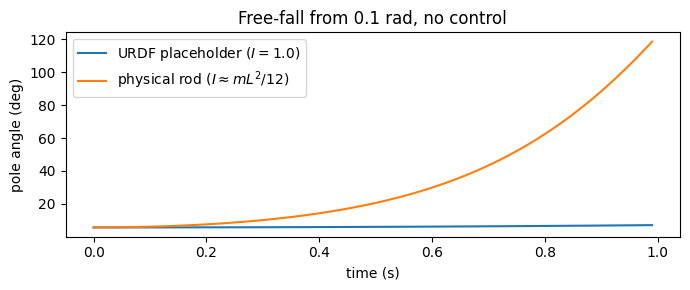

after 1.0 s: placeholder 7 deg, corrected 119 deg (fallen over)


In [3]:
def freefall(rob, n=100, dt=0.01):  # n=100 => t=1.0 s, matches the golden
    g = rob.functional_dynamics()
    z = jnp.zeros(2)

    def rk4(s):
        k1 = g(s, z)
        k2 = g(s + 0.5 * dt * k1, z)
        k3 = g(s + 0.5 * dt * k2, z)
        k4 = g(s + dt * k3, z)
        return s + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

    @jax.jit
    def run(s0):
        return jax.lax.scan(lambda s, _: (rk4(s), s[1]), s0, None, length=n)

    s_end, th = run(jnp.array([0.0, 0.1, 0.0, 0.0]))
    return np.asarray(s_end), np.asarray(th)


s_ph, th_ph = freefall(zoo.calibrated("cartpole"))  # URDF placeholder inertia
s_ok, th_ok = freefall(nj.calibrated_cartpole())  # physical rod + damping

# Validation: the functional dynamics reproduce the engine's committed golden
# (a placeholder-physics free-fall) bit-for-bit — same physics, not a look-alike.
golden = np.load(zoo.ROBOTS["cartpole"].URDF_PATH.with_name("golden_freefall.npz"))[
    "final_state"
]
print(
    f"functional vs committed golden: max|err| = {float(np.max(np.abs(s_ph - golden))):.2e}"
)

tf = np.arange(len(th_ph)) * 0.01
plt.figure(figsize=(7, 3))
plt.plot(tf, np.degrees(th_ph), label=r"URDF placeholder ($I=1.0$)")
plt.plot(tf, np.degrees(th_ok), label=r"physical rod ($I\approx mL^2/12$)")
plt.xlabel("time (s)")
plt.ylabel("pole angle (deg)")
plt.title("Free-fall from 0.1 rad, no control")
plt.legend()
plt.tight_layout()
plt.show()
print(
    f"after 1.0 s: placeholder {np.degrees(th_ph[-1]):.0f} deg, "
    f"corrected {np.degrees(th_ok[-1]):.0f} deg (fallen over)"
)

robot = nj.calibrated_cartpole()  # use the physically-corrected model from here on

### Step 2 — turn the robot into a *fast* environment

To train or optimise against the robot we need to step its dynamics millions of
times. The faithful one-shot path (`policies.S4.step`) rebuilds the simulator on
every call and costs ~2.5 s/step — hopeless for RL. Instead,
`Robot.functional_dynamics()` returns a **pure, `jit`/`vmap`-able** function
$f(\mathbf{s}, u)\to\dot{\mathbf{s}}$ that builds the MJX model once and then runs
in microseconds. We integrate it ourselves with fixed-step RK4.

We time it live below — this is the headline performance claim, demonstrated not
asserted.

In [4]:
f = robot.functional_dynamics()  # pure f(state, tau) -> dstate


def rk4(state, tau, dt):
    k1 = f(state, tau)
    k2 = f(state + 0.5 * dt * k1, tau)
    k3 = f(state + 0.5 * dt * k2, tau)
    k4 = f(state + dt * k3, tau)
    return state + dt / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)


# vmap one RK4 step over a batch of environments, jit the whole thing.
B = 512
vstep = jax.jit(jax.vmap(lambda s, u: rk4(s, jnp.array([u, 0.0]), 0.02)))
states = jnp.tile(jnp.array([0.0, 0.05, 0.0, 0.0]), (B, 1))
forces = jnp.zeros(B)
states = vstep(states, forces)
states.block_until_ready()  # compile

t0 = time.time()
for _ in range(200):
    states = vstep(states, forces)
states.block_until_ready()
per_env = (time.time() - t0) / 200 / B
print(
    f"vmapped MJX step: {per_env * 1e6:.2f} us / env-step  "
    f"({B / ((time.time() - t0) / 200):.0f} env-steps/s)"
)
print("compare: policies.S4.step is ~2.5 s/step — about a million times slower.")

vmapped MJX step: 1.87 us / env-step  (533912 env-steps/s)
compare: policies.S4.step is ~2.5 s/step — about a million times slower.


We already validated this primitive in Step 1 (it reproduced the engine's
committed free-fall golden to machine precision). Here we just confirm the
*corrected* upright is unstable — and now realistically fast: a $0.02\,$rad tilt
diverges in a fraction of a second, where the placeholder model barely moved.

In [5]:
@jax.jit
def grow(s0):
    def body(s, _):
        s2 = rk4(s, jnp.zeros(2), 0.01)
        return s2, s2[1]

    _, th = jax.lax.scan(body, s0, None, length=150)  # 1.5 s
    return th


thetas = np.asarray(grow(jnp.array([0.0, 0.02, 0.0, 0.0])))
print(
    f"corrected uncontrolled pole: theta 0.02 -> {thetas[-1]:.2f} rad in 1.5 s "
    "(diverges fast => unstable upright, now at a physical rate)"
)

corrected uncontrolled pole: theta 0.02 -> 2.74 rad in 1.5 s (diverges fast => unstable upright, now at a physical rate)


### Step 3 — the policy, and why it's *in the demo*

`jaxterity` ships **no** policy code by design — it is a calibrated-environment
provider, not a learning library. So the controller is a small, self-contained
PPO living entirely in `examples/nanojaxterity.py`: a two-layer MLP actor that
maps the (normalised) state to a discrete cart force $u\in\{-10, 0, +10\}\,$N, a
value critic, GAE advantages, and a clipped surrogate objective (Schulman 2017).

Training takes ~6 minutes; this notebook **loads the committed trained policy**
(`nanojaxterity_policy.eqx`) — per the publication-asset convention, the
pretrained weights *are* the artifact, so we never retrain here.

In [6]:
cfg = nj.Config()
policy = eqx.tree_deserialise_leaves(
    EX / "nanojaxterity_policy.eqx", nj.ActorCritic(jax.random.PRNGKey(0))
)
_, step = nj.make_env(robot, cfg)
force_of = np.asarray(nj.ACTIONS) * cfg.force
N = cfg.eval_steps  # closure constant => static scan length


@eqx.filter_jit
def greedy_rollout(start):
    def body(s, _):
        logits, _ = policy(s)
        a = jnp.argmax(logits)
        ns, _, _ = step(s, a)
        return ns, (ns, a)

    _, (traj, acts) = jax.lax.scan(body, jnp.asarray(start, float), None, length=N)
    return traj, acts  # leave as JAX arrays; convert to numpy outside the jit


traj_j, acts_j = greedy_rollout(jnp.array([0.0, cfg.eval_start_theta, 0.0, 0.0]))
traj = np.asarray(traj_j)
acts = np.asarray(acts_j)
forces = force_of[acts]
t = np.arange(cfg.eval_steps) * cfg.dt
print(
    f"max|theta| over {cfg.eval_steps * cfg.dt:.0f}s: {np.max(np.abs(traj[:, 1])):.4f} rad "
    f"(bound {cfg.theta_bound}) -> {'BALANCED' if np.max(np.abs(traj[:, 1])) < cfg.theta_bound else 'FELL'}"
)

max|theta| over 10s: 0.0472 rad (bound 0.1) -> BALANCED


### Run, plot, interpret

We plot the three signals that tell the whole story: the pole angle (the
*regulated* quantity), the cart position (the *actuator's* excursion), and the
commanded force (the *control effort*).

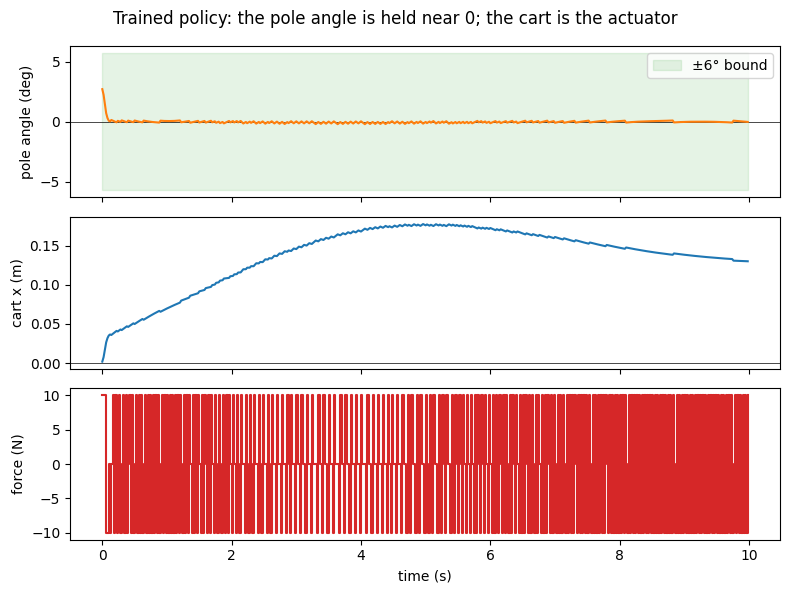

pole angle RMS: 0.19 deg
cart excursion: [0.00, 0.18] m


In [7]:
fig, ax = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].plot(t, np.degrees(traj[:, 1]), color="C1")
ax[0].fill_between(
    t,
    -np.degrees(cfg.theta_bound),
    np.degrees(cfg.theta_bound),
    color="C2",
    alpha=0.12,
    label=f"±{np.degrees(cfg.theta_bound):.0f}° bound",
)
ax[0].set_ylabel("pole angle (deg)")
ax[0].legend(loc="upper right")
ax[1].plot(t, traj[:, 0], color="C0")
ax[1].axhline(0, color="k", lw=0.5)
ax[1].set_ylabel("cart x (m)")
ax[2].step(t, forces, where="post", color="C3")
ax[2].set_ylabel("force (N)")
ax[2].set_xlabel("time (s)")
fig.suptitle("Trained policy: the pole angle is held near 0; the cart is the actuator")
fig.tight_layout()
plt.show()

print(f"pole angle RMS: {np.degrees(np.sqrt(np.mean(traj[:, 1] ** 2))):.2f} deg")
print(f"cart excursion: [{traj[:, 0].min():.2f}, {traj[:, 0].max():.2f}] m")

**Figure 1** — *top:* the pole angle stays inside the few-degree bound for
the whole episode (orange), i.e. the controller stabilises the unstable upright.
*Middle:* the cart stays **near centre** (within a few tens of cm) — it makes a
small corrective move and *stops*, because the corrected model has joint
friction. (On the original placeholder model the frictionless cart instead
glided away — fixing the physics fixed the drift; see the aside below.)
*Bottom:* the commanded force **chatters** between $\pm 10$ N — the snappy
corrected pole needs near-continuous correction, and a discrete 3-action policy
can only approximate a small push by rapidly alternating the rails (bang-bang
"PWM"). It stabilises the pole, but it is not a *smooth* controller (see the
diagnostics next).

### Closed-loop diagnostics

A simulation can succeed while hiding a controller pathology. We run
`jaxonomy.diagnostics` on the force signal to check for two silent failure modes:
actuator **saturation** and control **oscillation**.

In [8]:
sat = analyze_saturation(forces, lower=-cfg.force, upper=cfg.force, name="cart force")
osc = analyze_control_oscillation(forces, t, name="cart force")
print(sat.summary() if hasattr(sat, "summary") else sat)
print(osc.summary() if hasattr(osc, "summary") else osc)

SaturationReport(saturated=75.4%, upper=37.8%, lower=37.6%, warn=True)
OscillationReport(crossings/s=37.27, warn=True)


/tmp/claude-501/ipykernel_83481/412431173.py:1: UserWarning: [analyze_saturation] cart force: 38% at upper=10, 38% at lower=-10. Total saturated: 75% of 500 samples. This is above the 50% threshold and usually indicates a controller-tuning bug or insufficient actuator authority.
  sat = analyze_saturation(forces, lower=-cfg.force, upper=cfg.force, name="cart force")
/tmp/claude-501/ipykernel_83481/412431173.py:2: UserWarning: [analyze_control_oscillation] cart force: 372 sign changes over 9.98 s = 37.27 crossings/s. This is above the 5.0/s threshold and usually indicates bang-bang behaviour (PD-gain or sign bug).
  osc = analyze_control_oscillation(forces, t, name="cart force")


> **Both checks fire (`warn=True`) — and we say so.** The force sits at a
> $\pm 10$ N rail ~75 % of the time and changes sign ~37×/s. The diagnostics'
> hint — "usually a tuning bug or insufficient actuator authority" — is worth
> taking seriously, but here it is the genuine character of *discrete bang-bang*
> control of a *fast* pole: with only three force choices the policy cannot
> apply a small push, so it dithers between the rails to synthesise one
> (PWM-style). It does stabilise the pole (top of Figure 1), but it is not a
> smooth controller. This is exactly the kind of thing these checks exist to
> surface — and the fix is a **continuous-action** policy (Exercise 2), which
> would produce a smooth, mostly-unsaturated force. (On the *placeholder*,
> sluggish model the same policy barely needed to act — saturation was ~4 %; the
> snappier physics is what makes the discrete controller work this hard.)

### The 3D view (MuJoCo)

The same calibrated model, rendered with MuJoCo and embedded below as an
animation (`examples/nanojaxterity_render.py` writes both an `.mp4` and a
notebook-friendly `.gif`). The red arrow is the policy's commanded force each
frame, from a fixed camera: the pole is held vertical while the cart makes a
small corrective move and stops. (Rendering is post-hoc — MuJoCo draws the poses
our policy produced; no physics here.)

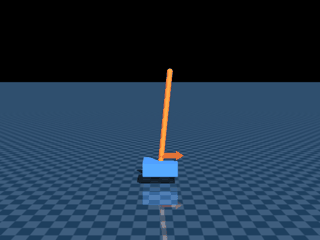

In [9]:
Image(filename=str(EX / "nanojaxterity.gif"))

*Video* — the trained policy balancing the corrected cartpole: blue cart,
orange pole, red force arrow. The pole is righted and held vertical while the
cart makes a small corrective move and stops.

## Robustness without retraining — one policy, many physical cartpoles

A controller trained on *one* calibration is only useful if it tolerates the
real robot being a bit different. We never retrain below: we take the committed
policy and drop it onto cartpoles with **off-nominal pole mass and length**,
built on the fly with `robot.with_parameters`, and measure the peak pole angle
after a fixed angular-velocity kick.

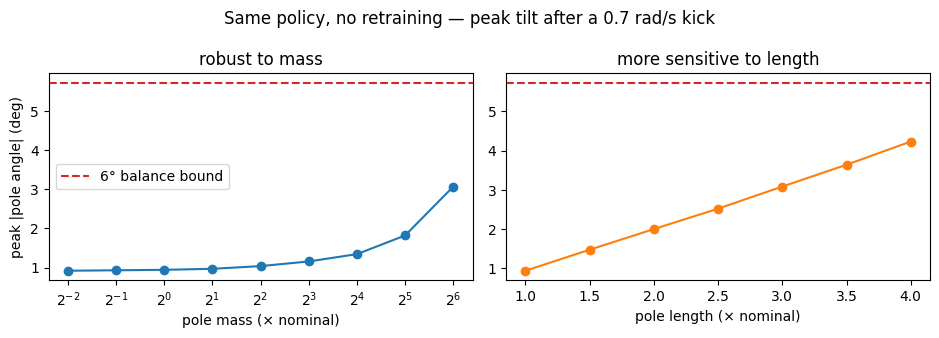

mass x64 peak 3.1 deg  |  length x4 peak 4.2 deg


In [10]:
def peak_tilt(variant, kick):
    _, step = nj.make_env(variant, cfg)

    @eqx.filter_jit
    def roll(s0):
        def body(s, _):
            logits, _ = policy(s)
            ns, _, _ = step(s, jnp.argmax(logits))
            return ns, s[1]

        _, th = jax.lax.scan(body, jnp.asarray(s0, float), None, length=cfg.eval_steps)
        return th

    return float(np.degrees(np.max(np.abs(np.asarray(roll([0.0, 0.0, 0.0, kick]))))))


def mass_variant(k):
    m = 0.1 * k
    return robot.with_parameters(
        {
            "pole.mass": jnp.asarray(m),
            "pole.inertia": jnp.diag(jnp.asarray([m / 12] * 3)),
        }
    )


KICK = 0.7  # rad/s angular-velocity perturbation
mass_x = np.array([0.25, 0.5, 1, 2, 4, 8, 16, 32, 64])
len_x = np.array([1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0])
mass_tilt = [peak_tilt(mass_variant(k), KICK) for k in mass_x]
len_tilt = [peak_tilt(longer_pole(robot, L), KICK) for L in len_x]

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
bound = np.degrees(cfg.theta_bound)
ax[0].plot(mass_x, mass_tilt, "o-", color="C0")
ax[0].axhline(bound, color="C3", ls="--", label=f"{bound:.0f}° balance bound")
ax[0].set_xscale("log", base=2)
ax[0].set_xlabel("pole mass (× nominal)")
ax[0].set_ylabel("peak |pole angle| (deg)")
ax[0].set_title("robust to mass")
ax[0].legend()
ax[1].plot(len_x, len_tilt, "o-", color="C1")
ax[1].axhline(bound, color="C3", ls="--")
ax[1].set_xlabel("pole length (× nominal)")
ax[1].set_title("more sensitive to length")
fig.suptitle(f"Same policy, no retraining — peak tilt after a {KICK} rad/s kick")
fig.tight_layout()
plt.show()
print(
    f"mass x64 peak {mass_tilt[-1]:.1f} deg  |  length x4 peak {len_tilt[-1]:.1f} deg"
)

**Figure 3** — *left:* the same policy balances a pole from **¼× to 64×
the nominal mass** with the peak tilt barely moving. *Right:* it tolerates a
range of *lengths* too, but the peak tilt climbs noticeably faster.

Why? An inverted pendulum's instability timescale is $\sqrt{L/g}$ — it depends
on the **length, not the mass** (just as all objects fall at the same rate). So
the angular dynamics the policy reacts to are essentially *mass-invariant*,
which is why a 64× heavier pole barely fazes it; **length**, which sets the
timescale, is the axis that matters. Push the kick harder ($\dot\theta=0.9$
rad/s) and the extremes finally topple — *length first.*

This isn't a party trick: it tells you **which calibration parameters you must
get right**. For this system the pole's length / inertia distribution matters
far more than its mass — so that is where telemetry calibration earns its keep,
and a robustness margin like this is exactly the sim-to-real budget you'd want
before deployment.

The same committed policy balancing a **2× longer pole** — a different
physical robot (taller, recoloured purple), no retraining:

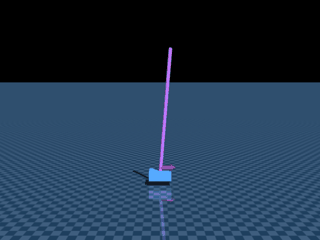

In [11]:
Image(filename=str(EX / "nanojaxterity_long.gif"))

## Why differentiable? A one-line autodiff demo

Because the whole simulator is JAX-native, $f(\mathbf{s}, u)$ is
**differentiable**. That is what makes gradient-based system identification,
trajectory optimisation, and analytic-gradient control possible on the *same*
model the policy trains on. Here is the Jacobian of the dynamics at the upright,
computed with `jax.jacfwd` in one line — note the $\partial\ddot\theta/\partial\theta
> 0$ entry, the unstable-equilibrium signature.

In [12]:
J = jax.jacfwd(lambda s: f(s, jnp.zeros(2)))(jnp.zeros(4))
J = np.asarray(J)
print("d(dstate)/d(state) at upright:\n", np.round(J, 3))
print(
    f"\nd(thetaddot)/d(theta) = {J[3, 1]:+.3f}  (> 0 => upright is unstable, matches Eq. 1)"
)

d(dstate)/d(state) at upright:
 [[ 0.0000e+00  0.0000e+00  1.0000e+00  0.0000e+00]
 [ 0.0000e+00  0.0000e+00  0.0000e+00  1.0000e+00]
 [ 0.0000e+00 -7.1900e-01 -7.8100e-01  7.0000e-03]
 [ 0.0000e+00  1.5809e+01  1.1720e+00 -1.6100e-01]]

d(thetaddot)/d(theta) = +15.809  (> 0 => upright is unstable, matches Eq. 1)


## A lesson worth its own heading: the physics *was* the controller bug

Our first attempt trained on the **placeholder** model (the geom-less, unit-
inertia, frictionless URDF). On it the agent could keep the pole up but the
frictionless cart drifted away, and aggressive attempts to make it return to
centre repeatedly *destabilised* PPO. We assumed it was a controls problem.

It was a **physics** problem. Once we set a realistic pole inertia and added
joint friction (`nj.calibrated_cartpole()`), the same PPO — barely re-tuned —
balanced *and* kept the cart near centre across every start we tried, because
the cart friction does most of the position-regulation for free. Garbage
dynamics make for garbage (or impossible) control. This is the whole argument
for calibration in one anecdote: **a controller is only as good as the model it
was trained on.**

## Failure modes (be specific)

- **The calibration is hand-set, not learned.** `calibrated_cartpole()` overrides
  the inertia/friction to *physically sensible* values — but they are guessed,
  not fit from a real cartpole's telemetry. The committed zoo calibration is
  still synthetic. Real sim-to-real needs recorded hardware data through the
  sysid recipes.
- **Large perturbations still have a limit.** The greedy policy is robust to the
  reset distribution it trained on (tilts to ~6°, kicks to ~0.3 rad/s); a much
  harder flick can still topple it, and discrete bang-bang force is coarser than
  a continuous controller (Exercise 2).

## What's novel — and what isn't

Let's be precise about the value, because it is easy to over-claim.

- **The controller is not novel.** A classical LQR balances this cartpole just as
  well; for a problem this simple, RL buys nothing. Learned control earns its
  keep on nonlinear, contact-rich systems (legs, hands), not here.
- **The value is the *vertical lane*.** One JAX-native stack carried us from a
  URDF → a *calibrated* robot model → a fast *differentiable* simulator → a
  trained policy, in a single readable file. The enabling primitive is
  `Robot.functional_dynamics()` (the ~$10^6\times$ speedup over the naive path).
- **Versus SOTA RL-sim stacks** (Brax, MJX Playground, Isaac): the simulation and
  RL machinery are comparable — we *use* MJX. What this stack adds is at the *ends*:
  **calibration from telemetry** upstream (grounding the sim to a physical
  machine) and **verified embedded deployment** downstream (the calibrated,
  attested artifact lowers to acados → signed C on an Arm chip via `jaxility`).
  Most RL-sim stacks focus on the fast-sim-plus-RL middle; this tutorial adds the
  two stages around it — calibration upstream and attested deployment downstream.

## Exercises

1. **Feel the physics lesson.** Train once on the *placeholder* model (swap
   `calibrated_cartpole()` back to `zoo.calibrated("cartpole")` in
   `examples/nanojaxterity.py`) and once on the corrected one. Compare the cart
   trajectories. How much of "good control" turned out to be "good model"?
2. **Continuous force (conceptual + code).** Replace the 3-action categorical
   policy with a Gaussian over a continuous force. Does the control-oscillation
   diagnostic go quiet? Why?
3. **Compare to LQR.** Linearise $f$ at the upright (we computed the Jacobian
   above), design an LQR gain, and overlay its angle trace on Figure 1. Which is
   smoother?
4. **Break it on purpose.** Find the smallest initial $\dot\theta$ for which the
   greedy policy topples. Relate it to the bang-bang force authority.
5. **Open-ended.** What would you need to add to make the *calibration* real for
   a physical cartpole, and how would you validate the sim-to-real gap?

## Key takeaways

- The cartpole is the "hello world" of a **vertical lane**: description →
  calibrated model → fast differentiable sim → learned controller.
- `Robot.functional_dynamics()` is the primitive that makes RL/optimisation on a
  calibrated robot model feasible (~$10^6\times$ faster than the faithful
  per-call path), and it reproduces the engine's physics bit-for-bit.
- The simulator is **differentiable** end-to-end (one-line Jacobian), which is
  what later, harder controllers will exploit.
- Be honest about scope: the controller isn't novel, the cart isn't
  position-regulated, and the calibration is synthetic — the *pipeline* is the
  contribution.

## Next steps

- `examples/nanojaxterity.py` — the full self-contained trainer (env + PPO).
- **Next in the roadmap:** hand the calibrated robot + trained policy to
  `jaxility`, which lowers it to acados and emits a signed C binary for an Arm
  target — the deployment end of the lane.

## References

1. Schulman et al., *Proximal Policy Optimization Algorithms*, 2017.
2. Schulman et al., *High-Dimensional Continuous Control Using GAE*, 2016.
3. Todorov, Erez, Tassa, *MuJoCo: A physics engine for model-based control*, IROS 2012.
4. Barto, Sutton, Anderson, *Neuronlike adaptive elements that can solve difficult
   learning control problems* (the cartpole), IEEE SMC, 1983.